## 1. 설정
포트와 각 단계의 값. 바꿀 게 있으면 여기만 고친다.

In [15]:
import threading
import time

import matplotlib.pyplot as plt
import numpy as np
import serial
from IPython.display import display
import ipywidgets as widgets
from ipyevents import Event
from scipy.signal import butter, sosfiltfilt, welch

PORT = "/dev/cu.usbserial-120"   # receiver 포트
BAUD = 921600

# 128쌍 중 쓰는 자리. 가운데·양끝 빈칸과 망가진 L-LTF +1번 제외
LLTF = np.r_[2:27, 38:64]       # 51개
HTLTF = np.r_[65:93, 100:128]   # 56개
SLOTS = np.r_[LLTF, HTLTF]      # 107개

# ① 튀는 값 제거 (Hampel)
HAMPEL_HALF = 3   # 앞뒤 3개씩 → 7개로 중앙값
MAD_LEN = 49      # 평소 벗어남은 최근 49개(약 1초)로
HAMPEL_K = 3      # 평소 벗어남의 3배 넘으면 튄 값
MAD_FLOOR = 1.0   # 세기가 정수에서 나와 값이 똑같이 반복되면 벗어남이 0이 되므로 최소 1로

# ② 스케일 변동 제거
SCALE_FIX_S = 30   # 이 시간까지 M을 누적, 이후 고정

# ③④⑤ 1분 묶음 처리
BLOCK_S, OVERLAP_S = 60, 15   # 60초마다 갱신, 직전 15초 겹침 → 75초씩 처리
LOW_HZ, HIGH_HZ = 0.1, 1.0
N_TOP = 10
EDGE_S = 5.0   # 묶음 양 끝 몇 초는 필터 가장자리라 점수·크기 계산에서 빼고, 이어 붙일 때도 안 씀

# 화면: 실시간 진폭 그래프로 보여줄 줄기와 시간 폭
SHOW_SC = ["L+15"]   # 수집이 잘 되는지 확인용 (여러 개 넣으면 위아래로 나란히)
SHOW_S = 30   # 최근 몇 초를 보여줄지
_loc = SLOTS % 64
SC_NAMES = [f"{'L' if i < len(LLTF) else 'HT'}{s:+d}" for i, s in enumerate(np.where(_loc < 32, _loc, _loc - 64))]
SHOW_IDX = [SC_NAMES.index(n) for n in SHOW_SC]

## ① 튀는 값 제거 (선언)
7개 중앙값으로 찾고, 앞뒤 정상값 평균으로 바꾼다. 약 0.06초 늦음.

In [16]:
win_amp, win_clip = [], []   # 최근 49개 줄 (가운데 = 끝에서 4번째)


def hampel_push(amp, clipped):
    """새 줄을 넣고, 가운데(3개 전) 줄이 정해지면 정리된 줄을 돌려준다. 창이 덜 찼으면 None"""
    win_amp.append(amp)
    win_clip.append(clipped)
    if len(win_amp) > MAD_LEN:
        win_amp.pop(0)
        win_clip.pop(0)
    if len(win_amp) < 2 * HAMPEL_HALF + 1:
        return None
    a = np.array(win_amp)
    w = np.where(np.array(win_clip), np.nan, a)   # 잘린 값은 계산에서 뺀다
    c = len(a) - 1 - HAMPEL_HALF                  # 가운데 줄 위치
    near = w[c - HAMPEL_HALF:c + HAMPEL_HALF + 1]  # 앞뒤 3개 + 가운데 = 7개
    x = a[c].copy()
    with np.errstate(all="ignore"):
        med = np.nanmedian(near, axis=0)
        mad = np.maximum(1.4826 * np.nanmedian(np.abs(w - med), axis=0), MAD_FLOOR)
        # 앞뒤 3개씩 중 잘리지 않고 튀지도 않은 값들의 평균
        nb = np.delete(near, HAMPEL_HALF, axis=0)
        nb = np.where(np.abs(nb - med) > HAMPEL_K * mad, np.nan, nb)
        fill = np.nanmean(nb, axis=0)
    fill = np.where(np.isnan(fill), med, fill)   # 정상 이웃이 하나도 없으면 중앙값으로
    bad = win_clip[c] | (np.abs(x - med) > HAMPEL_K * mad)
    bad &= ~np.isnan(fill)   # 7개가 전부 잘렸으면 대신할 값이 없으니 그대로 둔다
    x[bad] = fill[bad]
    return x

## ② 스케일 변동 제거 (선언)
패킷마다 107개 평균으로 나누고, 처음 30초 평균 크기 M을 곱한다.

In [17]:
m_sum, m_cnt = 0.0, 0


def scale_row(x, t):
    """Hampel 지난 107개 한 줄과 그 시각 → 패킷 공통 흔들림을 지운 한 줄"""
    global m_sum, m_cnt
    p = x.mean()
    if t <= SCALE_FIX_S:
        m_sum += p
        m_cnt += 1
    return x / p * (m_sum / m_cnt)

## ③④⑤ 1분 묶음 처리 (선언)
①② 결과가 1분 쌓일 때마다 직전 15초를 겹쳐 75초로: 0.1~1Hz 필터(앞뒤) → 줄기 점수 → 상위 N개 합치기 → 겹친 15초에서 이어 붙이기

In [18]:
final_t, final_y = np.empty(0), np.empty(0)   # 이어 붙인 최종 파형
blocks = []                                    # 묶음마다 고른 줄기 기록


def combine(x, fs):
    """①② 결과 한 묶음 (패킷 수, 107) → 최종 파형 1개, 고른 줄기 정보"""
    n = len(x)
    ramp = np.linspace(0, 1, n)[:, None]
    x = x - (x[:1] + (x[-1:] - x[:1]) * ramp)                          # 양 끝을 0으로 맞춰 가장자리 출렁임 줄임
    sos = butter(2, [LOW_HZ, HIGH_HZ], btype="bandpass", fs=fs, output="sos")
    f = sosfiltfilt(sos, x, axis=0, padtype="even", padlen=min(n - 1, int(10 * fs)))   # ③④ 앞뒤로 두 번
    e = int(EDGE_S * fs)
    mid = f[e:n - e] if n > 4 * e else f                               # 점수·크기는 가운데만으로
    F, P = welch(mid, fs=fs, nperseg=min(len(mid), int(30 * fs)), axis=0)
    band = (F >= 0.1) & (F <= 0.7)
    peak = F[band][np.argmax(P[band], axis=0)]
    total = P[(F >= LOW_HZ) & (F <= HIGH_HZ)].sum(axis=0)
    rhythm = np.array([P[np.abs(F - peak[k]) <= 0.05, k].sum() for k in range(f.shape[1])]) / total
    mu, sd = mid.mean(axis=0), mid.std(axis=0)
    z = (f - mu) / sd
    zm = (mid - mu) / sd
    cc = np.corrcoef(zm.T)
    np.fill_diagonal(cc, np.nan)
    score = rhythm * np.nanmean(np.abs(cc), axis=1)
    top = np.argsort(-score)[:N_TOP]
    sign = np.sign([np.corrcoef(zm[:, top[0]], zm[:, k])[0, 1] for k in top])
    weight = score[top] / score[top].sum()
    return (z[:, top] * sign * weight).sum(axis=1), dict(top=top.tolist(), sign=sign.tolist(), score=score[top].tolist())


def add_block(t, y):
    """새 묶음을 이어 붙임. 가장자리는 버리거나 비중 0에서 시작, 크기는 가운데 기준으로 1, 방향은 겹친 곳에서 맞춤"""
    global final_t, final_y
    mid = (t >= t[0] + EDGE_S) & (t <= t[-1] - EDGE_S)
    y = y / y[mid].std()
    keep = t <= t[-1] - EDGE_S                     # 끝(지금) 가장자리는 붙이지 않음 → 다음 묶음이 채움
    if len(final_t) == 0:
        keep &= t >= t[0] + EDGE_S                 # 기록 맨 앞 가장자리도 버림
    t, y = t[keep], y[keep]
    if len(final_t) == 0:
        final_t, final_y = t, y
        return
    n = int((t <= final_t[-1]).sum())              # 겹친 구간
    prev = final_y[-n:]
    ok = t[:n] >= t[0] + EDGE_S                    # 새 묶음 시작 가장자리는 비교에서 뺌
    if np.corrcoef(prev[ok], y[:n][ok])[0, 1] < 0:
        y = -y
    w = np.clip((t[:n] - t[0] - EDGE_S) / max(t[n - 1] - t[0] - EDGE_S, 1e-9), 0, 1)   # 가장자리 지나서부터 서서히
    final_y[-n:] = (1 - w) * prev + w * y[:n]
    final_t = np.concatenate([final_t, t[n:]])
    final_y = np.concatenate([final_y, y[n:]])


def process_until(end):
    """①② 결과가 end초까지 쌓였으면 [end - BLOCK_S - OVERLAP_S, 지금] 묶음을 처리. 처리했으면 True"""
    n = len(clean_list)
    if not n or t_list[n - 1] < end:
        return False
    t = np.array(t_list[:n])
    use = t >= end - BLOCK_S - OVERLAP_S
    tb, xb = t[use], np.array(clean_list[:n])[use]
    y, info = combine(xb, (len(tb) - 1) / (tb[-1] - tb[0]))
    add_block(tb, y)
    blocks.append(dict(start_s=float(tb[0]), end_s=float(tb[-1]), **info))
    return True


def blocker():
    end = BLOCK_S
    while not stop.is_set():
        if process_until(end):
            end += BLOCK_S
        time.sleep(1)

## 화면 (선언)
원본 세기는 1초마다 다시 그리고, 최종 호흡 파형은 1분 묶음이 새로 붙을 때마다 다시 그린다.

In [19]:
def show_amp():
    """최근 SHOW_S초, 고른 줄기들의 원본 진폭을 줄기마다 한 줄씩"""
    while not stop.is_set():
        n = len(amp_list)
        if n > 1:
            t = np.array(t_list[:n])
            use = t >= t[-1] - SHOW_S
            a = np.array(amp_list[:n])[use]
            for ax, k in zip(axs_a, SHOW_IDX):
                ax.clear()
                ax.plot(t[use], a[:, k], lw=0.6, color="k")
                ax.set_ylabel(SC_NAMES[k], fontsize=9)
                ax.grid(alpha=0.3)
            axs_a[0].set_title(f"amplitude (raw), last {SHOW_S} s   {n} packets", loc="left")
            axs_a[-1].set_xlabel("time (s)")
            axs_a[-1].set_xlim(max(0, t[-1] - SHOW_S), max(SHOW_S, t[-1]))
            view_a.update(fig_a)
        time.sleep(1)


def draw_final():
    """이어 붙인 최종 파형 + 라벨 배경을 다시 그림"""
    t, y = final_t, final_y
    n = len(t_list)
    lab, tt = np.array(label_list[:n]), np.array(t_list[:n])
    ax_w.clear()
    s0 = 0
    for i in range(1, len(lab) + 1):                      # 라벨 구간 배경색
        if i == len(lab) or lab[i] != lab[s0]:
            if lab[s0] in ("in", "ex"):
                ax_w.axvspan(tt[s0], tt[i - 1], color="tab:blue" if lab[s0] == "in" else "tab:orange", alpha=0.15, lw=0)
            s0 = i
    ax_w.plot(t, y, "k", lw=1.1)
    ax_w.grid(alpha=0.3)
    ax_w.set(xlim=(t[0], t[-1]), xlabel="time (s)   background: blue = in key, orange = ex key")
    ax_w.set_title(f"breathing waveform (all steps)  {len(blocks)} blocks", loc="left")
    view_w.update(fig_w)


def show_final():
    drawn = 0                                # 이미 그린 묶음 수
    while not stop.is_set():
        if len(blocks) > drawn and len(final_t):
            drawn = len(blocks)
            draw_final()
        time.sleep(5)

## 실행
**커널 재시작 후 위 셀들(설정, 파이프라인 선언)을 실행한 다음, 이 셀을 한 번만** 실행.
누르는 순간 수집이 시작되고, 아래에 라벨 상자 · 실시간 진폭 그래프 · 1분마다 갱신되는 최종 호흡 파형이 뜬다.
라벨: 마우스를 라벨 상자 위에 둔 채로 ← 누르고 있기 = in(들숨), → 누르고 있기 = ex(날숨), 안 누르면 none

HTML(value='<h3>&nbsp;label: none</h3>', layout=Layout(border_bottom='2px solid gray', border_left='2px solid …

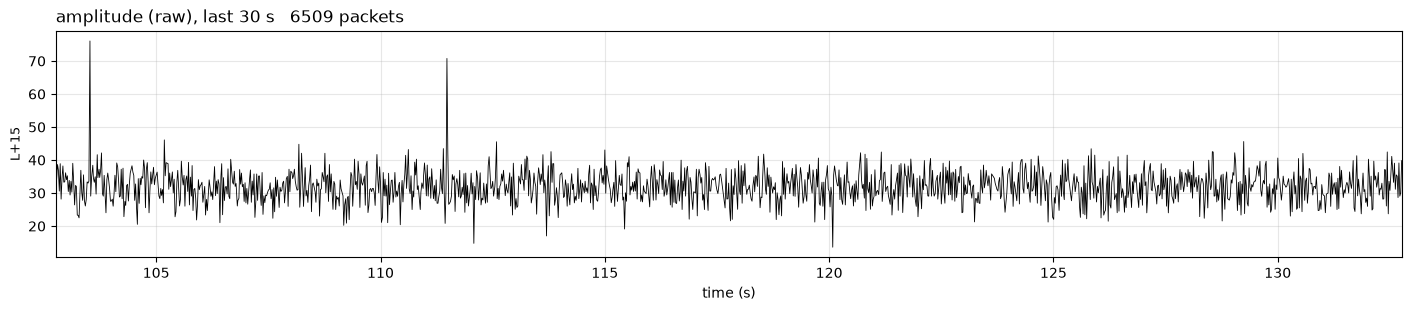

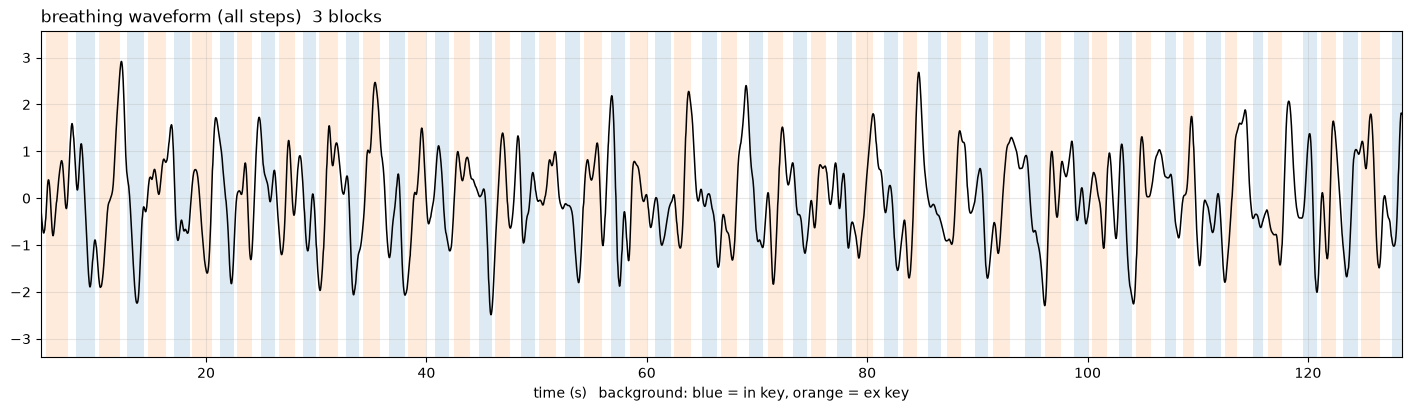

In [20]:
# ===== 시리얼 읽기 + 세기 + 정답 라벨 =====
t_list, label_list, amp_list = [], [], []   # 패킷마다 한 줄씩 누적 (시각, 라벨, 107개 세기)
clean_list = []   # ① 튀는 값 + ② 스케일 변동 제거 결과 (3패킷 늦게 채워짐, 같은 번호 = 같은 패킷)
stop = threading.Event()
label = "none"   # 지금 눌린 키의 라벨. 패킷이 들어올 때 이 값을 같이 기록

# 키보드 입력: 누르는 동안 in/ex, 떼면 none
KEYMAP = {"ArrowLeft": "in", "ArrowRight": "ex"}
pad = widgets.HTML(layout=widgets.Layout(width="420px", height="60px", border="2px solid gray"))
pad.value = "<h3>&nbsp;label: none</h3>"


def on_key(e):
    global label
    if e["key"] in KEYMAP:
        label = KEYMAP[e["key"]] if e["type"] == "keydown" else "none"
        pad.value = f"<h3>&nbsp;label: {label}</h3>"


keys = Event(source=pad, watched_events=["keydown", "keyup"], prevent_default_action=True)
keys.on_dom_event(on_key)


def parse(line):
    """'CSI,seq,lost,ts,rssi,fwi,len,[256개]' → (ts, 107개 세기, 107개 잘림 여부). 깨진 줄은 None"""
    if not line.startswith("CSI,") or "[" not in line:
        return None
    head, body = line.split("[", 1)
    fields = head.split(",")
    values = body.split("]")[0].split()
    if len(fields) < 7 or len(values) != 256:
        return None
    try:
        ts = int(fields[3])
        pairs = np.array(values, dtype=float).reshape(128, 2)[SLOTS]
    except ValueError:
        return None
    clipped = ((pairs >= 127) | (pairs <= -128)).any(axis=1)   # 둘 중 하나라도 int8 끝값이면 잘린 것
    return ts, np.hypot(pairs[:, 0], pairs[:, 1]), clipped


def reader():
    ser = serial.Serial()
    ser.port, ser.baudrate, ser.timeout = PORT, BAUD, 1
    ser.dtr = ser.rts = False   # 포트 열 때 ESP32 리셋 방지
    ser.open()
    prev, t = None, 0.0
    try:
        while not stop.is_set():
            p = parse(ser.readline().decode("ascii", "ignore"))
            if p is None:
                continue
            ts, amp, clipped = p
            if prev is not None:
                t += ((ts - prev) % 2**32) / 1e6   # ESP32 시계 한 바퀴 넘어가도 이어짐
            prev = ts
            t_list.append(t)
            label_list.append(label)
            c = hampel_push(amp, clipped)   # ①: 3패킷 전 줄이 정리돼서 나옴 (처음 6개는 None)
            if c is not None:
                c = scale_row(c, t_list[len(clean_list)])   # ②: 패킷 공통 흔들림 제거 (그 줄의 시각)
                clean_list.append(c)
            amp_list.append(amp)   # 마지막에 추가: len(amp_list) 까지는 시각·라벨·세기가 다 채워져 있음
    finally:
        ser.close()


# ===== 화면 띄우고 시작 =====
display(pad)   # 라벨 상자

# 화면 2개: 실시간 원본 세기 / 1분마다 갱신되는 최종 호흡 파형
fig_a, axs_a = plt.subplots(len(SHOW_IDX), 1, figsize=(14, max(3, 1.3 * len(SHOW_IDX))), sharex=True,
                            squeeze=False, layout="constrained")
axs_a = axs_a[:, 0]   # 줄기가 1개여도 목록으로
view_a = display(fig_a, display_id=True)
plt.close(fig_a)
fig_w, ax_w = plt.subplots(figsize=(14, 4), layout="constrained")
view_w = display(fig_w, display_id=True)
plt.close(fig_w)

# 읽기 + 1분 묶음 처리 + 화면 갱신을 뒤에서 시작
for target in (reader, blocker, show_amp, show_final):
    threading.Thread(target=target, daemon=True).start()

## 종료
멈추고 포트를 닫은 뒤, 남은 구간까지 처리해서 `날짜_시각/` 폴더에 두 개 저장
- amplitude.csv : 시각, 키보드 라벨, 107개 진폭
- waveform.png  : 최종 호흡 파형 그래프 (①②③④⑤ 다 거친 것)

In [21]:
import csv
from datetime import datetime
from pathlib import Path

stop.set()
time.sleep(1.5)   # 읽기 스레드가 멈추고 포트를 닫을 때까지

# 마지막 묶음이 덜 찬 부분도 처리해서 이어 붙임 (10초 이상 남았을 때)
if clean_list and t_list[len(clean_list) - 1] - (final_t[-1] if len(final_t) else 0) >= 10:
    process_until(t_list[len(clean_list) - 1])
if len(final_t):   # 화면 스레드는 이미 멈췄으니 마지막 구간까지 한 번 더 그림
    draw_final()

run_dir = Path(f"{datetime.now():%Y%m%d_%H%M%S}")
run_dir.mkdir()

# 1) 진폭 + 키보드 라벨
n = len(amp_list)
with open(run_dir / "amplitude.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["time_s", "label", *[f"c{i}" for i in range(len(SLOTS))]])
    for t, lab, row in zip(t_list[:n], label_list[:n], amp_list[:n]):
        w.writerow([f"{t:.6f}", lab, *[f"{v:.6g}" for v in row]])

# 2) 최종 호흡 파형 그래프 (①②③④⑤ 다 거친 것)
fig_w.savefig(run_dir / "waveform.png", dpi=110)

run_dir, n

(PosixPath('20261123_114106'), 6553)